# 01 - EAGLE-I outage data quality

What values we have, what is null or missing, and anything that looks wrong.
Data: `eaglei/outages_YYYY.parquet` (customers out per county, every 15 min), plus the
EAGLE-I reference files (MCC customer counts, coverage history, DQI).

Each year is 0.4-6M rows, so we go one year at a time and keep only small summaries.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.data import load_outages, load_customer_counts, load_census, load_coverage_history, path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

## 1. One pass over every year

In [2]:
summary, per_county, monthly, nulls = [], [], [], []

for y in C.YEARS:
    df = load_outages([y])
    out = df["customers_out"]
    t = df["run_start_time"]
    slots = (t.max() - t.min()) / pd.Timedelta("15min") + 1   # possible 15-min readings in this file

    summary.append({
        "year": y,
        "rows": len(df),
        "counties": df["fips_code"].nunique(),
        "first": t.min(),
        "last": t.max(),
        "minutes_seen": sorted(t.dt.minute.unique()),
        "null_customers_out": out.isna().sum(),
        "null_time": t.isna().sum(),
        "null_fips": df["fips_code"].isna().sum(),
        "zeros": (out == 0).sum(),
        "negative": (out < 0).sum(),
        "non_integer": (out.dropna() % 1 != 0).sum(),
        "dup_county_time": df.duplicated(["fips_code", "run_start_time"]).sum(),
        "max_out": out.max(),
    })

    c = df.groupby(["fips_code", "county", "state"], dropna=False).agg(
        readings=("customers_out", "size"),
        nulls=("customers_out", lambda s: s.isna().sum()),
        max_out=("customers_out", "max"),
    ).reset_index()
    c["year"] = y
    c["pct_of_possible"] = 100 * c["readings"] / slots
    per_county.append(c)

    m = df.groupby(t.dt.month).agg(rows=("fips_code", "size"), counties=("fips_code", "nunique"))
    m["year"] = y
    monthly.append(m.reset_index(names="month"))

    n = df[out.isna()]
    nulls.append(n.groupby([n["state"], n["run_start_time"].dt.month]).size()
                  .rename("null_rows").reset_index().assign(year=y))

summary = pd.DataFrame(summary)
per_county = pd.concat(per_county, ignore_index=True)
monthly = pd.concat(monthly, ignore_index=True)
nulls = pd.concat(nulls, ignore_index=True)
summary

,year,rows,counties,first,last,minutes_seen,null_customers_out,null_time,null_fips,zeros,negative,non_integer,dup_county_time,max_out
0,2014,358659,410,2014-11-01 04:00:00,2014-12-31 00:00:00,"[0, 15, 30, 45]",0,0,0,0,0,0,0,23816.0
1,2015,2580145,449,2015-01-01 00:00:00,2015-12-31 00:00:00,"[0, 15, 30, 45]",0,0,0,0,0,0,0,92954.0
2,2016,2960707,449,2016-01-01 00:00:00,2016-12-31 00:00:00,"[0, 15, 30, 45]",0,0,0,0,0,0,0,467041.0
3,2017,3388524,508,2017-01-01 00:00:00,2017-12-31 00:00:00,"[0, 15, 30, 45]",28781,0,0,0,0,0,0,1777800.0
4,2018,4553450,508,2018-01-01 00:00:00,2018-12-31 00:00:00,"[0, 15, 30, 45]",315048,0,0,0,0,0,0,135215.0
5,2019,4808385,525,2019-01-01 00:00:00,2019-12-31 00:00:00,"[0, 15, 30, 35, 45]",275065,0,0,0,0,0,0,137536.0
6,2020,5194354,523,2020-01-01 00:00:00,2020-12-31 00:00:00,"[0, 15, 16, 30, 31, 45, 46]",429447,0,0,0,0,0,0,178832.0
7,2021,4832707,523,2021-01-01 00:00:00,2021-12-31 00:00:00,"[0, 15, 16, 30, 45]",218042,0,0,0,0,0,0,83500.0
8,2022,5289340,527,2022-01-01 00:00:00,2022-12-31 23:45:00,"[0, 15, 30, 45]",0,0,0,342871,0,0,0,456573.0
9,2023,5412736,527,2023-01-01 00:00:00,2023-12-31 23:45:00,"[0, 15, 30, 31, 45]",0,0,0,195956,0,0,0,138851.0


## 2. Columns: types and example values (2024)

In [3]:
df = load_outages([2024])
print(df.dtypes, "\n")
print(df.head(), "\n")
print(df["customers_out"].describe().round(1))

fips_code                    str
county                       str
state                        str
customers_out            float32
run_start_time    datetime64[us]
dtype: object 

  fips_code   county    state  customers_out      run_start_time
0     01001  Autauga  Alabama            2.0 2024-01-01 00:15:00
1     01001  Autauga  Alabama            2.0 2024-01-01 00:30:00
2     01001  Autauga  Alabama            2.0 2024-01-01 00:45:00
3     01001  Autauga  Alabama            4.0 2024-01-02 03:15:00
4     01001  Autauga  Alabama            4.0 2024-01-02 03:30:00 



count    5837620.0
mean         479.1
std         6549.7
min            0.0
25%            2.0
50%            4.0
75%           26.0
max       520308.0
Name: customers_out, dtype: float64


**How big are the values?** Most readings are a handful of customers; large values are rare.

In [4]:
bins = [0, 1, 10, 100, 1_000, 10_000, 100_000, 10_000_000]
print(pd.cut(df["customers_out"], bins, right=False).value_counts().sort_index())

customers_out
[0, 1)                 214507
[1, 10)               3471635
[10, 100)             1386077
[100, 1000)            549112
[1000, 10000)          167724
[10000, 100000)         44736
[100000, 10000000)       3829
Name: count, dtype: int64


## 3. Missing readings (rows that are not there at all)

A full year has 35,040 15-min readings per county (35,136 in a leap year). EAGLE-I seems to
skip the row when nothing is out, so most counties have far fewer rows. `pct_of_possible` is
the share of 15-min slots that have a row.

In [5]:
per_county.groupby("year")["pct_of_possible"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2014,410.0,15.2,19.5,0.0,3.2,7.9,17.9,98.8
2015,449.0,16.4,20.0,0.0,3.2,9.0,21.1,98.4
2016,449.0,18.8,21.1,0.0,3.9,10.8,25.7,98.7
2017,508.0,19.1,19.9,0.0,5.0,12.7,24.6,92.6
2018,508.0,25.7,21.6,0.0,9.8,19.7,34.4,99.4
2019,525.0,26.2,20.7,0.0,12.1,20.9,33.8,99.8
2020,523.0,28.3,21.5,0.4,12.8,22.7,37.5,99.8
2021,523.0,26.4,21.4,0.1,11.7,20.5,34.2,99.8
2022,527.0,28.6,21.7,0.0,12.9,24.2,39.7,99.7


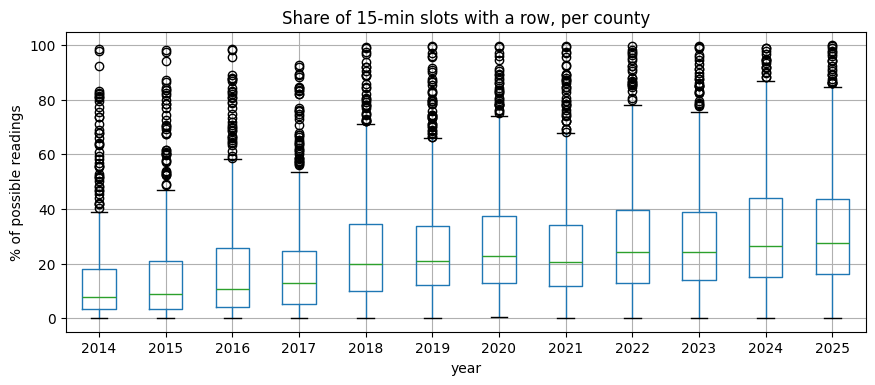

In [6]:
per_county.boxplot(column="pct_of_possible", by="year", figsize=(10, 4))
plt.title("Share of 15-min slots with a row, per county")
plt.suptitle("")
plt.ylabel("% of possible readings")
plt.show()

**Counties reporting each month.** Gaps here are whole months where the data is thin.

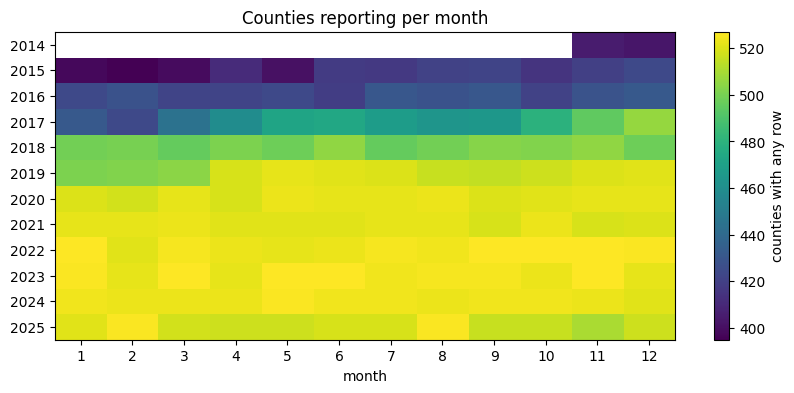

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,405.0,403.0
2015,398.0,395.0,399.0,411.0,401.0,418.0,417.0,421.0,422.0,415.0,420.0,424.0
2016,424.0,428.0,422.0,422.0,424.0,419.0,431.0,428.0,431.0,421.0,429.0,432.0
2017,432.0,424.0,445.0,459.0,472.0,474.0,468.0,464.0,465.0,480.0,495.0,506.0
2018,499.0,500.0,496.0,501.0,498.0,505.0,496.0,499.0,503.0,502.0,505.0,498.0
2019,501.0,502.0,504.0,519.0,522.0,521.0,520.0,516.0,515.0,517.0,520.0,521.0
2020,520.0,518.0,522.0,519.0,523.0,522.0,522.0,523.0,520.0,521.0,522.0,522.0
2021,522.0,522.0,523.0,521.0,521.0,521.0,522.0,522.0,519.0,523.0,519.0,520.0
2022,527.0,521.0,525.0,523.0,522.0,523.0,525.0,524.0,527.0,527.0,527.0,526.0


In [7]:
grid = monthly.pivot(index="year", columns="month", values="counties")
plt.figure(figsize=(10, 4))
plt.imshow(grid, aspect="auto", cmap="viridis")
plt.colorbar(label="counties with any row")
plt.xticks(range(12), range(1, 13))
plt.yticks(range(len(grid)), grid.index)
plt.xlabel("month")
plt.title("Counties reporting per month")
plt.show()
grid

**Last day of the year.** In 2014-2021 the files stop at Dec 31 00:00, so Dec 31 is missing.

In [8]:
for y in [2018, 2024]:
    t = load_outages([y], columns=["run_start_time"])["run_start_time"]
    print(y, "rows on Dec 30:", (t.dt.strftime("%m-%d") == "12-30").sum(),
          "| Dec 31:", (t.dt.strftime("%m-%d") == "12-31").sum())

2018 rows on Dec 30: 9305 | Dec 31: 91


2024 rows on Dec 30: 18830 | Dec 31: 17270


**Odd timestamps.** A few rows are stamped at :16, :31, :35 or :46 instead of 15-min marks.

In [9]:
odd = [(y, (load_outages([y], columns=["run_start_time"])["run_start_time"].dt.minute % 15 != 0).sum())
       for y in [2019, 2020, 2021, 2023]]
pd.DataFrame(odd, columns=["year", "odd_minute_rows"])

,year,odd_minute_rows
0,2019,23
1,2020,754
2,2021,61
3,2023,165


## 4. Null `customers_out` (row exists, value is empty)

In [10]:
summary[["year", "rows", "null_customers_out"]].assign(
    pct_null=lambda d: (100 * d["null_customers_out"] / d["rows"]).round(2))

,year,rows,null_customers_out,pct_null
0,2014,358659,0,0.00
1,2015,2580145,0,0.00
2,2016,2960707,0,0.00
3,2017,3388524,28781,0.85
4,2018,4553450,315048,6.92
5,2019,4808385,275065,5.72
6,2020,5194354,429447,8.27
7,2021,4832707,218042,4.51
8,2022,5289340,0,0.00
9,2023,5412736,0,0.00


In [11]:
nulls.pivot_table(index="year", columns="state", values="null_rows", aggfunc="sum", fill_value=0)

state,Alabama,Florida,Georgia,North Carolina,South Carolina,Tennessee
year,,,,,,
2017,586,18940,5369,703,999,2184
2018,73339,85646,78501,15565,19884,42113
2019,14078,30568,138868,42740,17548,31263
2020,38463,73842,115059,109410,31138,61535
2021,54611,44796,49244,23323,5575,40493
2025,7251,36811,100814,45722,207890,90946


In [12]:
nulls.pivot_table(index="year", columns="run_start_time", values="null_rows", aggfunc="sum", fill_value=0)

run_start_time,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2017,0,0,0,0,0,0,0,0,0,0,5483,23298
2018,46980,95343,17549,6269,9304,13502,13345,11889,23922,21190,29609,26146
2019,27600,24806,13558,88135,6642,11396,28892,14625,8947,10773,8781,30910
2020,99410,17218,65175,46243,55276,35859,15609,12566,20609,10441,26827,24214
2021,11300,37961,21855,30884,25254,7999,13686,9167,6724,15894,23260,14058
2025,42470,17273,67891,51296,73792,43165,49306,24267,13428,26801,29466,50279


Are nulls a few counties that are always null, or scattered? (share of each county's rows that are null)

In [13]:
has_null = per_county[per_county["nulls"] > 0].copy()
has_null["pct_null"] = 100 * has_null["nulls"] / has_null["readings"]
has_null.groupby("year")["pct_null"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2017,500.0,3.3,12.7,0.0,0.1,0.3,0.7,100.0
2018,500.0,11.2,18.2,0.0,0.9,3.5,13.8,100.0
2019,520.0,10.6,14.0,0.0,1.8,5.1,14.5,100.0
2020,521.0,13.4,16.6,0.1,2.9,7.7,17.1,100.0
2021,521.0,9.0,14.6,0.0,1.3,3.2,9.9,100.0
2025,527.0,12.6,21.1,0.0,1.0,3.4,12.6,100.0


## 5. Counties

Which study-area counties never show up, and does each FIPS code keep one name?

In [14]:
census = load_census()
study = census.drop_duplicates("fips_code")[["fips_code", "county_name"]]
seen = set(per_county["fips_code"])
print(f"{len(seen)} of {len(study)} study-area counties appear in EAGLE-I at least once")
study[~study["fips_code"].isin(seen)]

529 of 534 study-area counties appear in EAGLE-I at least once


,fips_code,county_name
468,47085,"Humphreys County, Tennessee"
469,47039,"Decatur County, Tennessee"
479,47071,"Hardin County, Tennessee"
504,47005,"Benton County, Tennessee"
519,47135,"Perry County, Tennessee"


In [15]:
print("FIPS codes not in the census list:", sorted(seen - set(study["fips_code"])))
names = per_county.groupby("fips_code")[["county", "state"]].nunique()
names[(names > 1).any(axis=1)]

FIPS codes not in the census list: []


,county,state
fips_code,,


Counties per year by state, against the number of counties each state has.

In [16]:
per_county.pivot_table(index="year", columns="state", values="fips_code", aggfunc="nunique")

state,Alabama,Florida,Georgia,North Carolina,South Carolina,Tennessee
year,,,,,,
2014,22,65,155,86,46,36
2015,30,67,157,99,46,50
2016,29,67,157,99,46,51
2017,65,67,158,100,46,72
2018,65,67,157,100,46,73
2019,66,67,159,100,46,87
2020,65,67,159,100,46,86
2021,65,67,159,100,46,86
2022,66,67,159,100,46,89


## 6. Customer counts (MCC): the denominator for "% of customers out"

In [17]:
mcc = load_customer_counts()
mcc["fips_code"] = mcc["County_FIPS"].str.zfill(5)
mcc["Customers"] = pd.to_numeric(mcc["Customers"])
mcc = mcc[mcc["fips_code"].isin(study["fips_code"])]
print(f"MCC has {len(mcc)} of {len(study)} study counties")
study[~study["fips_code"].isin(mcc["fips_code"])]

MCC has 528 of 534 study counties


,fips_code,county_name
319,37075,"Graham County, North Carolina"
332,37099,"Jackson County, North Carolina"
335,37173,"Swain County, North Carolina"
341,37113,"Macon County, North Carolina"
343,37175,"Transylvania County, North Carolina"
371,37087,"Haywood County, North Carolina"


County-years where the peak outage is more than the county's total customers (impossible, so a data problem or an MCC that is too low).

In [18]:
peaks = per_county.merge(mcc[["fips_code", "Customers"]], on="fips_code", how="left")
peaks["peak_share"] = peaks["max_out"] / peaks["Customers"]
print(peaks["peak_share"].describe().round(3))
peaks[peaks["peak_share"] > 1].sort_values("peak_share", ascending=False)[
    ["year", "fips_code", "county", "state", "max_out", "Customers", "peak_share"]].head(20)

count    5912.000
mean        2.169
std        74.534
min         0.000
25%         0.075
50%         0.180
75%         0.397
max      5477.500
Name: peak_share, dtype: float64


,year,fips_code,county,state,max_out,Customers,peak_share
5285,2024,37089,Henderson,North Carolina,131460.0,24.0,5477.500000
2660,2019,37089,Henderson,North Carolina,21165.0,24.0,881.875000
3184,2020,37089,Henderson,North Carolina,19644.0,24.0,818.500000
2149,2018,37089,Henderson,North Carolina,15685.0,24.0,653.541667
4231,2022,37089,Henderson,North Carolina,11430.0,24.0,476.250000
5812,2025,37089,Henderson,North Carolina,10372.0,24.0,432.166667
1156,2016,37089,Henderson,North Carolina,9604.0,24.0,400.166667
4758,2023,37089,Henderson,North Carolina,9024.0,24.0,376.000000
1642,2017,37089,Henderson,North Carolina,8533.0,24.0,355.541667
708,2015,37089,Henderson,North Carolina,6473.0,24.0,269.708333


In [19]:
print("county-years with peak > all customers, by state:")
peaks[peaks["peak_share"] > 1]["state"].value_counts()

county-years with peak > all customers, by state:


state
North Carolina    248
Georgia            78
Florida            46
South Carolina     21
Tennessee          16
Alabama            14
Name: count, dtype: int64

Sanity check MCC against Census housing units: a county should have roughly 1 or more
customers per housing unit (homes plus businesses).

In [20]:
housing = census[census["acs_year"] == 2023][["fips_code", "county_name", "housing_units"]]
check = housing.merge(mcc[["fips_code", "Customers"]], on="fips_code", how="left")
check["customers_per_home"] = check["Customers"] / check["housing_units"]
check["state"] = check["fips_code"].str[:2].map(C.STATES)
print(check.groupby("state")["customers_per_home"].agg(
    median="median", below_half=lambda s: (s < 0.5).sum(), counties="size").round(2))
check.sort_values("customers_per_home").head(15)

       median  below_half  counties
state                              
AL       1.09           0        67
FL       1.21           0        67
GA       1.23           0       159
NC       0.50          48       100
SC       1.22           0        46
TN       1.16           0        95


,fips_code,county_name,housing_units,Customers,customers_per_home,state
337,37089,"Henderson County, North Carolina",57338,24.0,0.000419,NC
293,37001,"Alamance County, North Carolina",75456,925.0,0.012259,NC
357,37129,"New Hanover County, North Carolina",117236,2544.0,0.021700,NC
324,37063,"Durham County, North Carolina",149150,6008.0,0.040282,NC
383,37181,"Vance County, North Carolina",19423,863.0,0.044432,NC
352,37119,"Mecklenburg County, North Carolina",491721,28172.0,0.057293,NC
384,37183,"Wake County, North Carolina",481999,46622.0,0.096726,NC
311,37037,"Chatham County, North Carolina",35013,3797.0,0.108445,NC
310,37035,"Catawba County, North Carolina",72028,8165.0,0.113359,NC
355,37125,"Moore County, North Carolina",49419,5708.0,0.115502,NC


## 7. EAGLE-I's own coverage and data-quality scores

`coverage_history.csv`: share of each state's customers that EAGLE-I tracks (from 2018 on).

In [21]:
cov = load_coverage_history()
cov = cov[cov["state"].isin(C.STATES.values())]
cov["year"] = pd.to_datetime(cov["year"], format="%m/%d/%y").dt.year
cov.pivot(index="year", columns="state", values="max_pct_covered")

state,AL,FL,GA,NC,SC,TN
year,,,,,,
2018,0.79,0.97,0.90,0.82,0.99,0.55
2019,0.81,0.97,0.86,0.90,0.99,0.73
2020,0.81,0.97,0.88,0.91,0.99,0.73
2021,0.81,0.98,0.90,0.92,0.99,0.73
2022,0.81,0.98,0.91,0.92,0.99,0.75


`DQI.csv`: data quality index per FEMA region. All six study states are in **FEMA Region 4**.

In [22]:
dqi = pd.read_csv(path("eaglei/DQI.csv"))
dqi[dqi["fema"] == 4]

,fema,year,success_rate,percent_enabled,spatial_precision,cust_coverage,max_covered,total_customers,DQI
15,4,2018,98.861757,98.118301,78.191252,85.274387,27610605,32378544,74.674709
16,4,2019,98.794257,86.897518,71.365230,89.215870,29304643,32846895,65.047792
17,4,2020,98.700305,99.562188,76.823177,90.135368,30044515,33332659,77.485160
18,4,2021,99.456306,99.063035,76.919332,90.771997,30614057,33726323,85.155162
19,4,2022,98.928670,98.153542,76.742177,91.236277,31073335,34058092,79.172999


## 8. Summary

**Clean**
- Same 5 columns and types in all 12 years (this confirms the 2024 release matches).
- No null FIPS or timestamps, no negative or fractional counts, no duplicate county + time rows.
- Every FIPS code is a real study-area county and keeps one name.

**Problems to handle**
1. **North Carolina customer counts (MCC) are wrong.** 48 of 100 NC counties have under 0.5
   customers per home (Henderson: 24 customers for 57k homes); every other state is about 1.1-1.2.
   6 western NC counties have no MCC at all.
   -> For NC, use another denominator (e.g. Census housing units, or the county's highest outage seen).
2. **Some peaks are more than 100% of customers even where MCC looks fine** (123 county-years outside NC,
   248 in NC). Mostly hurricanes and small rural counties, e.g. Miami-Dade during Irma (2017): 1.78M out
   vs 951k customers. Early EAGLE-I likely double-counted some utilities. -> Cap peak share at 100% and flag these.
3. **Missing rows are mostly "nothing out".** Counties have rows for only about 15-33% of 15-min slots,
   and true zeros appear only from 2022 on. Before 2022 a missing row probably means 0.
4. **Nulls vs zeros changed over time.** 2017-2021 and 2025 have null `customers_out` (up to 8% of rows,
   spread over all states and months); 2022-2024 have zeros instead. Probably the same thing coded two ways;
   confirm before treating null as 0.
5. **Coverage grows**, mainly in Tennessee (36 -> 90 of 95 counties) and Alabama (22 -> 66 of 67).
   2014 only covers Nov-Dec. Five Tennessee counties never appear.
   EAGLE-I's own coverage is lowest in TN (55-75% of customers) and AL (about 80%).
6. **Dec 31 is missing in 2014-2021** (files stop at Dec 31 00:00).
7. A few hundred rows have odd minutes (:16, :31, :35, :46); round them to the nearest 15 min.